# Q2. CNN versus MLP (25 marks)

We use the same CIFAR-10 split as Q1: 45,000 training and 5,000 validation images with seed 26001. The official test set is reserved for the final comparison.

In [8]:
from pathlib import Path
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 26001
DATA_FOLDER = Path("data")
RESULTS = Path("results_q2")
RESULTS.mkdir(exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Seed:", SEED)
print("PyTorch version:", torch.__version__)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

Device: cpu
Seed: 26001
PyTorch version: 2.15.0+cpu


# Load CIFAR-10

In [9]:
# We keep the original images as tensors and apply our own transformations below.
base_train = datasets.CIFAR10(root=str(DATA_FOLDER), train=True,
                              download=True, transform=transforms.ToTensor())
labels = np.array(base_train.targets)
all_indices = np.arange(len(base_train))

train_indices, val_indices = train_test_split(
    all_indices, train_size=45000, test_size=5000,
    random_state=SEED, stratify=labels
)
assert len(train_indices) == 45000 and len(val_indices) == 5000
assert len(np.intersect1d(train_indices, val_indices)) == 0

q1_split_path = Path("results/split_seed_26001.npz")
if q1_split_path.exists():
    with np.load(q1_split_path) as q1_split:
        assert np.array_equal(train_indices, q1_split["train_indices"]), "Q1 training split does not match."
        assert np.array_equal(val_indices, q1_split["val_indices"]), "Q1 validation split does not match."
    print("Q2 split matches the saved Q1 split.")
else:
    print("Q1 split file not found here; split recreated using the Q1 method and seed.")

np.savez(RESULTS / "split_seed_26001.npz", train_indices=train_indices,
         val_indices=val_indices, seed=SEED)
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Class counts in validation:", np.bincount(labels[val_indices]))

Q2 split matches the saved Q1 split.
Training images: 45000
Validation images: 5000
Class counts in validation: [500 500 500 500 500 500 500 500 500 500]


# Image transformations

In [10]:
# Fixed CIFAR-10 normalization values.
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

permutation = torch.randperm(32 * 32, generator=torch.Generator().manual_seed(SEED))
np.save(RESULTS / "pixel_permutation.npy", permutation.numpy())

def transform_image(image, condition):
    # image has shape [3, 32, 32] with values from 0 to 1.
    if condition == "grayscale":
        gray = 0.299 * image[0] + 0.587 * image[1] + 0.114 * image[2]
        image = gray.unsqueeze(0).repeat(3, 1, 1)
    elif condition == "shuffled":
        image = image.reshape(3, 32 * 32)[:, permutation].reshape(3, 32, 32)
    elif condition != "clean":
        raise ValueError("Unknown image condition")
    return (image - MEAN) / STD

class CIFARCondition(Dataset):
    def __init__(self, base_dataset, indices, condition):
        self.base_dataset = base_dataset
        self.indices = indices
        self.condition = condition

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.base_dataset[int(self.indices[index])]
        return transform_image(image, self.condition), label

def make_loader(dataset, shuffle=False):
    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=0, pin_memory=(DEVICE.type == "cuda"),
                      generator=generator)

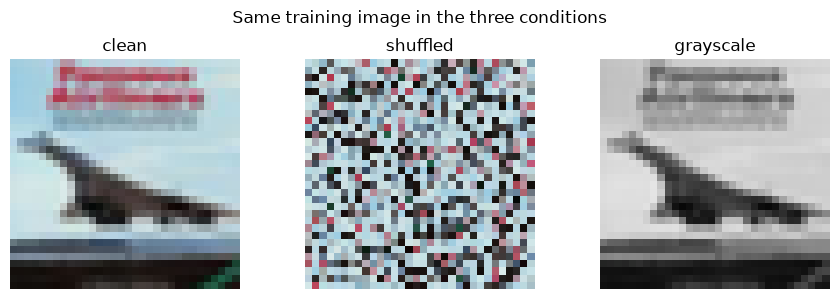

Class: airplane


In [11]:
# Show one TRAINING image, not a test image.
original, label = base_train[int(train_indices[0])]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, condition in zip(axes, ["clean", "shuffled", "grayscale"]):
    normalized = transform_image(original, condition)
    image = (normalized * STD + MEAN).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(condition)
    ax.axis("off")
fig.suptitle("Same training image in the three conditions")
fig.tight_layout()
fig.savefig(RESULTS / "example_transformations.png", dpi=160)
plt.show()
print("Class:", base_train.classes[label])

# Define the MLP and CNN

## Q2(a). Fair comparison on clean images

The MLP has 357,638 trainable parameters and the CNN has 356,810, a difference of about 0.23%. Both use the same split, pixel inputs, AdamW optimizer, learning rate, batch size and 20-epoch budget; checkpoints are selected by validation loss. This matches parameters and training settings, although the architectures do different amounts of computation.

**Explanation to test:** The CNN may perform better because its convolution filters detect local patterns and reuse them across image locations, while the MLP receives flattened pixels.

In [12]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * 32 * 32, 116),
            nn.ReLU(),
            nn.Linear(116, 10)
        )

    def forward(self, x):
        return self.layers(x)

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.layers(x)

def make_model(name):
    if name == "MLP":
        return MLP()
    if name == "CNN":
        return CNN()
    raise ValueError("Unknown model")

def count_parameters(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

model_table = pd.DataFrame([
    {"Model": name, "Trainable parameters": count_parameters(make_model(name))}
    for name in ["MLP", "CNN"]
])
display(model_table)
model_table.to_csv(RESULTS / "model_parameters.csv", index=False)
mlp_count = count_parameters(MLP())
cnn_count = count_parameters(CNN())
print(f"Parameter difference: {abs(mlp_count - cnn_count) / mlp_count * 100:.2f}% of the MLP size")

,Model,Trainable parameters
0,MLP,357638
1,CNN,356810


Parameter difference: 0.23% of the MLP size


# Training

In [13]:
BATCH_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.0001
CONDITIONS = ["clean", "shuffled", "grayscale"]
MODEL_NAMES = ["MLP", "CNN"]

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels_batch in loader:
        images, labels_batch = images.to(DEVICE), labels_batch.to(DEVICE)
        scores = model(images)
        total_loss += criterion(scores, labels_batch).item()
        correct += (scores.argmax(dim=1) == labels_batch).sum().item()
        total += labels_batch.size(0)
    return total_loss / total, correct / total

def train_one_epoch(model, loader, optimizer):
    model.train()
    criterion = nn.CrossEntropyLoss()
    total_loss = 0.0
    correct = 0
    total = 0
    for images, labels_batch in loader:
        images, labels_batch = images.to(DEVICE), labels_batch.to(DEVICE)
        optimizer.zero_grad()
        scores = model(images)
        loss = criterion(scores, labels_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * labels_batch.size(0)
        correct += (scores.argmax(dim=1) == labels_batch).sum().item()
        total += labels_batch.size(0)
    return total_loss / total, correct / total

def fit_model(model_name, condition):
    set_seed(SEED)
    model = make_model(model_name).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    train_set = CIFARCondition(base_train, train_indices, condition)
    val_set = CIFARCondition(base_train, val_indices, condition)
    train_loader = make_loader(train_set, shuffle=True)
    val_loader = make_loader(val_set)
    best_val_loss = float("inf")
    history = []
    start = time.time()

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
        val_loss, val_acc = evaluate(model, val_loader)
        history.append({"epoch": epoch, "train_loss": train_loss, "train_acc": train_acc,
                        "val_loss": val_loss, "val_acc": val_acc})
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({"state_dict": model.state_dict(), "epoch": epoch,
                        "val_loss": val_loss, "condition": condition, "model": model_name},
                       RESULTS / f"{model_name}_{condition}_best.pt")
        print(f"{model_name:3s} | {condition:9s} | epoch {epoch:2d}/{EPOCHS} | "
              f"train {train_acc:.3f} | val {val_acc:.3f} | val loss {val_loss:.3f}", flush=True)

    pd.DataFrame(history).to_csv(RESULTS / f"{model_name}_{condition}_history.csv", index=False)
    print(f"Finished in {(time.time() - start) / 60:.1f} minutes.\n")
    return pd.DataFrame(history)

# Train all six models

## Q2(b). Disturb spatial structure; Q2(c). Remove color

For Q2(b), one fixed permutation is applied to pixel positions in every image and all color channels, preserving the RGB values but disrupting the original spatial neighborhoods. **Prediction made before the comparison:** the CNN advantage should shrink, while the MLP may change less. Both models are trained again from scratch and the same transformation is used for validation and test images.

For Q2(c), every image is converted to grayscale and repeated across three channels. Both models are retrained. This tests whether color contributes to performance while retaining non-color spatial cues; it cannot prove that the CNN relies on shape alone.

In [14]:
histories = {}
for condition in CONDITIONS:
    for model_name in MODEL_NAMES:
        print(f"\nStarting {model_name} on {condition} images")
        histories[(model_name, condition)] = fit_model(model_name, condition)
print("All six training runs are complete.")


Starting MLP on clean images
MLP | clean     | epoch  1/20 | train 0.411 | val 0.448 | val loss 1.585
MLP | clean     | epoch  2/20 | train 0.486 | val 0.472 | val loss 1.531
MLP | clean     | epoch  3/20 | train 0.516 | val 0.491 | val loss 1.481
MLP | clean     | epoch  4/20 | train 0.534 | val 0.502 | val loss 1.451
MLP | clean     | epoch  5/20 | train 0.555 | val 0.506 | val loss 1.421
MLP | clean     | epoch  6/20 | train 0.572 | val 0.515 | val loss 1.438
MLP | clean     | epoch  7/20 | train 0.581 | val 0.504 | val loss 1.448
MLP | clean     | epoch  8/20 | train 0.595 | val 0.518 | val loss 1.424
MLP | clean     | epoch  9/20 | train 0.609 | val 0.501 | val loss 1.492
MLP | clean     | epoch 10/20 | train 0.616 | val 0.508 | val loss 1.515
MLP | clean     | epoch 11/20 | train 0.628 | val 0.500 | val loss 1.515
MLP | clean     | epoch 12/20 | train 0.636 | val 0.511 | val loss 1.502
MLP | clean     | epoch 13/20 | train 0.646 | val 0.513 | val loss 1.529
MLP | clean     | epo

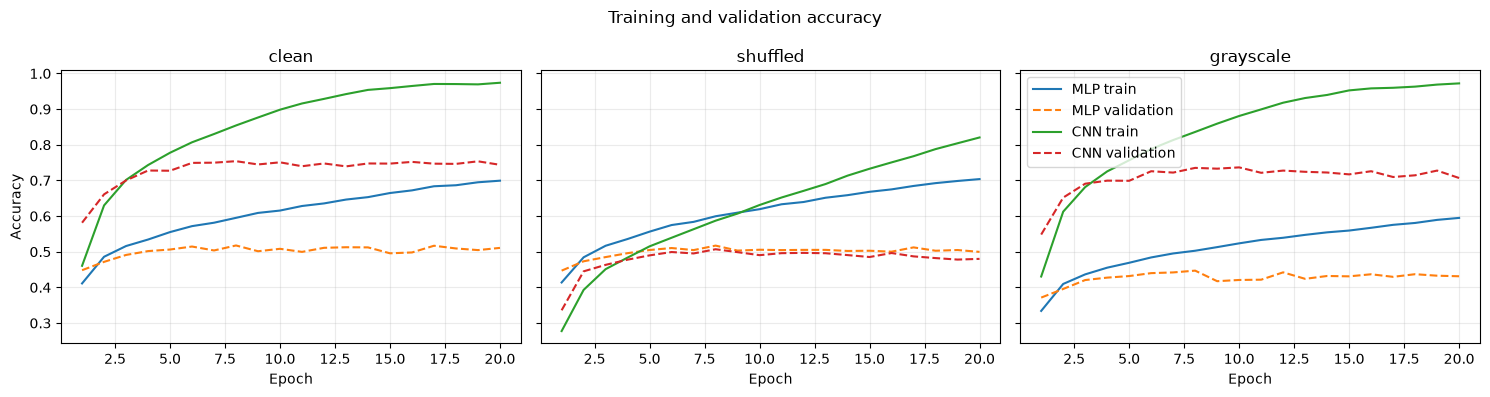

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, condition in zip(axes, CONDITIONS):
    for model_name in MODEL_NAMES:
        history = histories[(model_name, condition)]
        ax.plot(history["epoch"], history["train_acc"], label=f"{model_name} train")
        ax.plot(history["epoch"], history["val_acc"], "--", label=f"{model_name} validation")
    ax.set_title(condition)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Accuracy")
axes[-1].legend()
fig.suptitle("Training and validation accuracy")
fig.tight_layout()
fig.savefig(RESULTS / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

# Final test evaluation

In [16]:
test_base = datasets.CIFAR10(root=str(DATA_FOLDER), train=False,
                             download=True, transform=transforms.ToTensor())
test_indices = np.arange(len(test_base))

@torch.no_grad()
def predict_test(model, loader):
    model.eval()
    predictions, true_labels, confidence = [], [], []
    for images, labels_batch in loader:
        probabilities = torch.softmax(model(images.to(DEVICE)), dim=1)
        max_probability, predicted = probabilities.max(dim=1)
        predictions.extend(predicted.cpu().numpy())
        confidence.extend(max_probability.cpu().numpy())
        true_labels.extend(labels_batch.numpy())
    return np.array(predictions), np.array(true_labels), np.array(confidence)

results = []
prediction_details = {}
for condition in CONDITIONS:
    test_set = CIFARCondition(test_base, test_indices, condition)
    test_loader = make_loader(test_set)
    for model_name in MODEL_NAMES:
        checkpoint = torch.load(RESULTS / f"{model_name}_{condition}_best.pt",
                                map_location=DEVICE, weights_only=False)
        model = make_model(model_name).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"])
        predicted, actual, confidence = predict_test(model, test_loader)
        correct = predicted == actual
        prediction_details[(model_name, condition)] = (predicted, actual, confidence)
        results.append({"Condition": condition, "Model": model_name,
                        "Parameters": count_parameters(model), "Selected epoch": checkpoint["epoch"],
                        "Test accuracy": correct.mean(), "Test error rate": 1 - correct.mean(),
                        "Mean confidence (correct)": confidence[correct].mean() if correct.any() else np.nan,
                        "Mean confidence (wrong)": confidence[~correct].mean() if (~correct).any() else np.nan})

results_table = pd.DataFrame(results)
results_table.to_csv(RESULTS / "q2_test_results.csv", index=False)
display(results_table.round(4))

,Condition,Model,Parameters,Selected epoch,Test accuracy,Test error rate,Mean confidence (correct),Mean confidence (wrong)
0,clean,MLP,357638,5,0.5065,0.4935,0.6237,0.4520
1,clean,CNN,356810,6,0.7490,0.2510,0.8564,0.6146
2,shuffled,MLP,357638,8,0.5177,0.4823,0.6740,0.4999
3,shuffled,CNN,356810,8,0.5132,0.4868,0.6398,0.4737
4,grayscale,MLP,357638,8,0.4351,0.5649,0.5831,0.4432
5,grayscale,CNN,356810,6,0.7211,0.2789,0.8299,0.5882


# Compare errors and confidence

Test accuracy and the CNN–MLP difference:


Model,CNN,MLP,CNN minus MLP
Condition,,,
clean,0.7490,0.5065,0.2425
shuffled,0.5132,0.5177,-0.0045
grayscale,0.7211,0.4351,0.2860


Test accuracy by class:


Condition   clean        shuffled        grayscale       
Model         MLP    CNN      MLP    CNN       MLP    CNN
Class                                                    
airplane    0.521  0.780    0.579  0.558     0.437  0.744
automobile  0.544  0.865    0.595  0.590     0.526  0.871
bird        0.412  0.579    0.388  0.358     0.336  0.470
cat         0.328  0.551    0.318  0.310     0.240  0.574
deer        0.414  0.746    0.479  0.408     0.407  0.756
dog         0.406  0.582    0.383  0.410     0.291  0.620
frog        0.541  0.856    0.572  0.647     0.517  0.792
horse       0.549  0.816    0.603  0.572     0.537  0.759
ship        0.677  0.862    0.689  0.727     0.549  0.790
truck       0.673  0.853    0.571  0.552     0.511  0.835

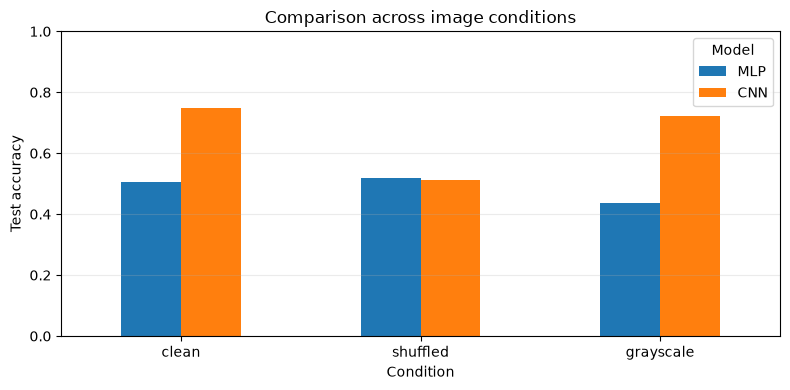

In [17]:
accuracy_table = results_table.pivot(index="Condition", columns="Model", values="Test accuracy")
accuracy_table = accuracy_table.reindex(CONDITIONS)
accuracy_table["CNN minus MLP"] = accuracy_table["CNN"] - accuracy_table["MLP"]
print("Test accuracy and the CNN–MLP difference:")
display(accuracy_table.round(4))
accuracy_table.to_csv(RESULTS / "accuracy_comparison.csv")

class_rows = []
for (model_name, condition), (predicted, actual, confidence) in prediction_details.items():
    for class_id, class_name in enumerate(test_base.classes):
        mask = actual == class_id
        class_rows.append({"Condition": condition, "Model": model_name, "Class": class_name,
                           "Accuracy": (predicted[mask] == actual[mask]).mean()})
class_table = pd.DataFrame(class_rows)
class_table.to_csv(RESULTS / "per_class_test_accuracy.csv", index=False)
print("Test accuracy by class:")
display(class_table.pivot(index="Class", columns=["Condition", "Model"], values="Accuracy").round(3))

fig, ax = plt.subplots(figsize=(8, 4))
accuracy_table[["MLP", "CNN"]].plot.bar(ax=ax)
ax.set_ylabel("Test accuracy")
ax.set_ylim(0, 1)
ax.set_title("Comparison across image conditions")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(RESULTS / "test_accuracy_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## Q2(a). Answer: clean images

The CNN achieved **74.90%** test accuracy and **25.10%** error, compared with **50.65%** accuracy and **49.35%** error for the MLP. Its advantage was **24.25 percentage points**. This is consistent with local filters and weight sharing being useful for natural image structure, although the comparison also changes architecture and compute.

## Q2(b). Answer: shuffled pixels

After retraining on the fixed spatial permutation, the CNN reached **51.32%** test accuracy and the MLP **51.77%**. The CNN advantage changed from +24.25 to **−0.45 percentage points**. The CNN fell by 23.58 points, while the MLP changed by +1.12 points. This agrees with the stated prediction and supports the explanation that preserving local spatial neighborhoods helps the CNN. It does not prove that spatial structure is the only difference between the models.

## Q2(c). Answer: grayscale and confidence

On grayscale images, the CNN reached **72.11%** accuracy (27.89% error), while the MLP reached **43.51%** (56.49% error). Compared with clean images, accuracy fell by 2.79 points for the CNN and 7.14 points for the MLP. Color was useful in these experiments, while the CNN retained substantial predictive performance without it. For example, CNN bird accuracy fell from **57.9% to 47.0%**.

The CNN's mean confidence on incorrect predictions was **61.46%** for clean images and **58.82%** for grayscale images. These are average maximum softmax scores, not calibrated probabilities of correctness. The models were retrained for grayscale, so the results do not establish that the CNN uses shape alone.

**Conclusion:** The clean CNN advantage almost disappeared after spatial shuffling but remained large in grayscale. Together, these results support the importance of spatial structure, while also showing that removing color changes performance.